In [8]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive (2).zip


In [9]:
import zipfile

with zipfile.ZipFile("archive.zip", "r") as z:
    z.extractall()

print("Extracted successfully!")

Extracted successfully!


In [10]:
import os

print(os.listdir())

['.config', 'archive (1).zip', 'archive (2).zip', 'Netflix_data.csv', 'archive.zip', 'sample_data']


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Netflix_data.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (7789, 11)


,Show_Id,Category,Title,Director,Cast,Country,Release_Date,Rating,Duration,Type,Description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,07:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [14]:
print(df.columns.tolist())

['Show_Id', 'Category', 'Title', 'Director', 'Cast', 'Country', 'Release_Date', 'Rating', 'Duration', 'Type', 'Description']


Category
Movie      5379
TV Show    2410
Name: count, dtype: int64


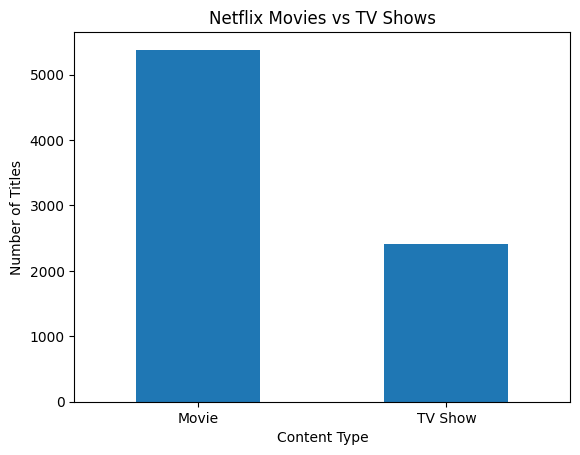

In [15]:
import matplotlib.pyplot as plt

df.columns = df.columns.str.strip()

if "Category" in df.columns:
    col = "Category"
elif "type" in df.columns:
    col = "type"
elif "Type" in df.columns:
    col = "Type"
else:
    print("Column names:", df.columns.tolist())
    col = None

if col:
    counts = df[col].value_counts()
    print(counts)

    counts.plot(kind="bar")
    plt.title("Netflix Movies vs TV Shows")
    plt.xlabel("Content Type")
    plt.ylabel("Number of Titles")
    plt.xticks(rotation=0)
    plt.show()

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Show_Id', 'Category', 'Title', 'Director', 'Cast', 'Country', 'Release_Date', 'Rating', 'Duration', 'Type', 'Description']


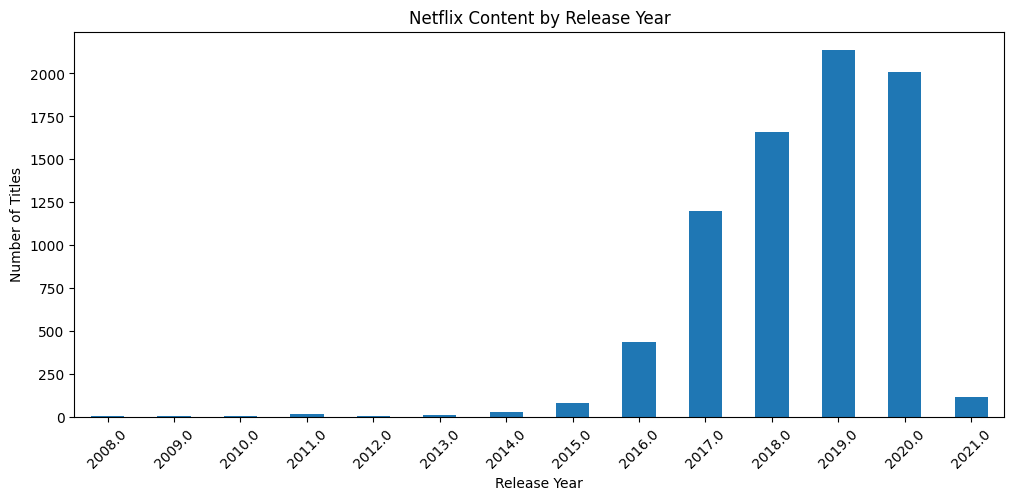

In [19]:
df["Release_Date"] = pd.to_datetime(
    df["Release_Date"], errors="coerce"
)

df["Release_Year"] = df["Release_Date"].dt.year

year_counts = df["Release_Year"].value_counts().sort_index()

year_counts.tail(20).plot(kind="bar", figsize=(12, 5))

plt.title("Netflix Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

Country
United States     3298
India              990
United Kingdom     723
Canada             412
France             349
Japan              287
Spain              215
South Korea        212
Germany            199
Mexico             154
Name: count, dtype: int64


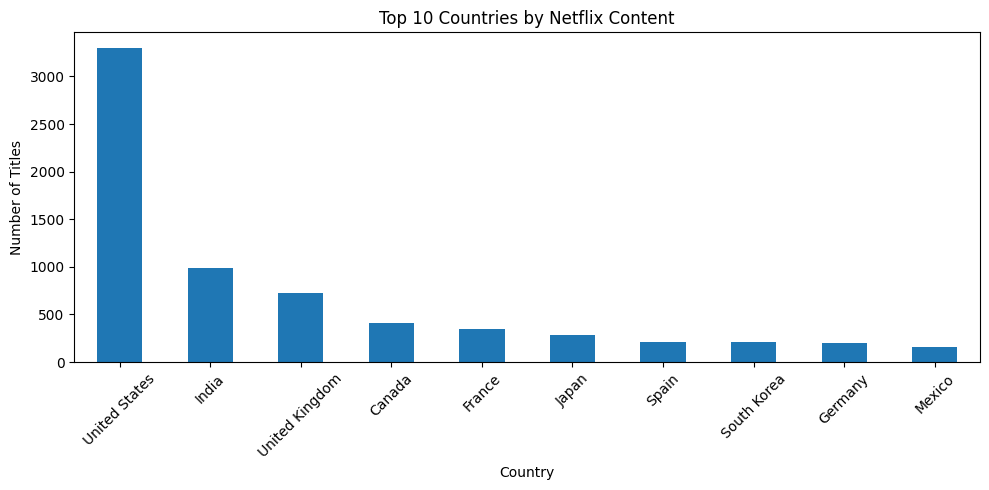

In [20]:
import matplotlib.pyplot as plt

country_counts = (
    df["Country"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

top_countries = country_counts.value_counts().head(10)

print(top_countries)

top_countries.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Rating
TV-MA    2865
TV-14    1931
TV-PG     806
R         665
PG-13     386
TV-Y      280
TV-Y7     271
PG        247
TV-G      194
NR         84
Name: count, dtype: int64


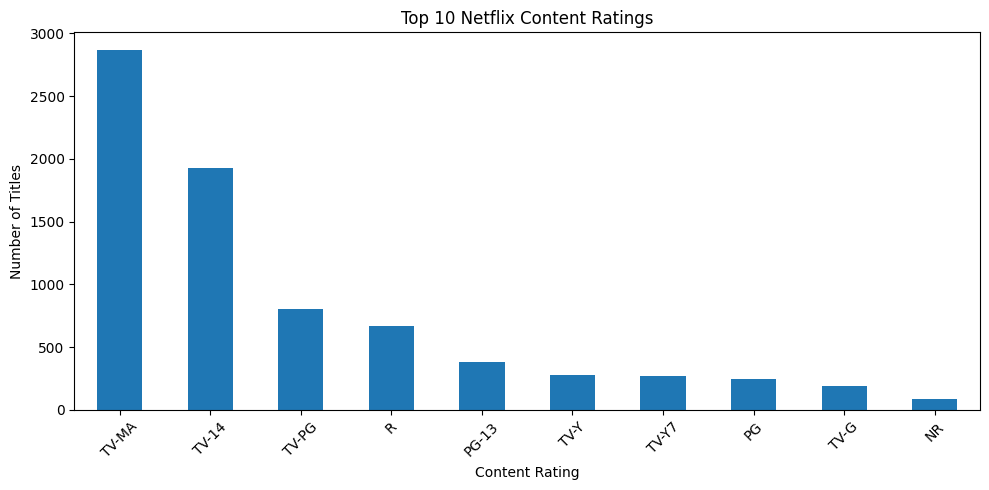

In [21]:
import matplotlib.pyplot as plt

rating_counts = df["Rating"].value_counts().head(10)

print(rating_counts)

rating_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Missing Values in Each Column:
Show_Id            0
Category           0
Title              0
Director        2388
Cast             718
Country          507
Release_Date      98
Rating             7
Duration           0
Type               0
Description        0
Release_Year      98
dtype: int64


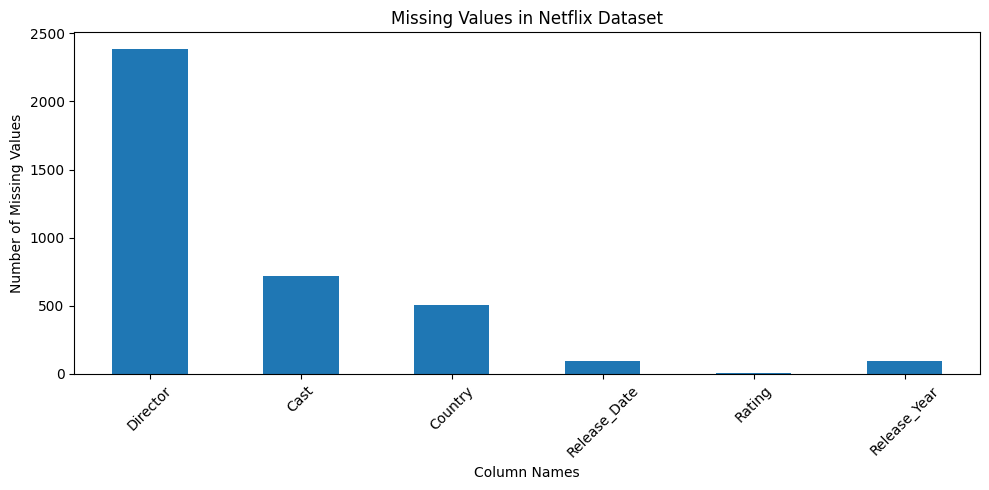

In [22]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

# Visualize missing values
missing_values[missing_values > 0].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Missing Values in Netflix Dataset")
plt.xlabel("Column Names")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
# Check missing values before cleaning
print("Before Cleaning:")
print(df.isnull().sum())

# Fill missing values in text columns
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].fillna("Unknown")

# Remove duplicate rows
df = df.drop_duplicates()

print("\nAfter Cleaning:")
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Before Cleaning:
Show_Id            0
Category           0
Title              0
Director        2388
Cast             718
Country          507
Release_Date      98
Rating             7
Duration           0
Type               0
Description        0
Release_Year      98
dtype: int64

After Cleaning:
Missing values: 196
Duplicate rows: 0
Dataset shape: (7787, 12)


In [24]:
print("NETFLIX EDA MINI PROJECT")
print("------------------------")

print("\n1. Total rows and columns:")
print(df.shape)

print("\n2. Movies vs TV Shows:")
print(df["Category"].value_counts()
      if "Category" in df.columns
      else df["type"].value_counts()
      if "type" in df.columns
      else "Check your dataset column names")

print("\n3. Missing values:")
print(df.isnull().sum().sum())

print("\n4. Duplicate rows:")
print(df.duplicated().sum())

NETFLIX EDA MINI PROJECT
------------------------

1. Total rows and columns:
(7787, 12)

2. Movies vs TV Shows:
Category
Movie      5377
TV Show    2410
Name: count, dtype: int64

3. Missing values:
196

4. Duplicate rows:
0


Conclusion

This mini project explores Netflix Movies and TV Shows data using Python, Pandas, and Matplotlib.

The project includes:

- Dataset loading and inspection
- Missing value and duplicate analysis
- Movies vs TV Shows comparison
- Release year analysis
- Country-wise content analysis
- Content rating analysis
- Data visualization using bar charts

Through this project, I learned the basics of data cleaning, exploratory data analysis, and visualization. The graphs help identify patterns in the Netflix dataset.